# ELN errors and independent-source transfer

Executed research analysis on real local inputs or committed aggregate reports. Historical/validation scope is labeled explicitly. No test rescoring occurs. Use the isolated repository environment plus Jupyter, pandas and matplotlib.

In [1]:
from pathlib import Path
import os, json, hashlib, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
assert (ROOT / 'pyproject.toml').exists()
os.chdir(ROOT)
for path in [ROOT, ROOT / 'src']:
    if str(path) not in sys.path: sys.path.insert(0, str(path))
FIGURES = ROOT / 'docs' / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)
def read_json(path):
    return json.loads(Path(path).read_text(encoding='utf-8'))
def show_figure(fig, name):
    path = FIGURES / (name + '.png')
    fig.tight_layout()
    fig.savefig(path, dpi=140, bbox_inches='tight')
    plt.close(fig)
    display(Image(filename=str(path)))
print('Executed analysis; Python', sys.version.split()[0])
print('Only aggregate outputs and figures are retained; raw rows/weights remain ignored.')


Executed analysis; Python 3.14.2
Only aggregate outputs and figures are retained; raw rows/weights remain ignored.


## Retrospective ELN evaluation
The procedure was frozen at commit 15cf75a before this release. The 130-row test was observed previously, so this is retrospective. All values below are actual tracked aggregate results, not notebook-computed predictions or newly scored data.

,mae_percentage_points,rmse_percentage_points,r2,rows
model,,,,
Retained GNN,24.641868,29.273375,0.027048,130
Selected forest,23.864459,28.987835,0.045936,130
Development median,25.622923,29.887282,-0.014189,130


Actual graph checkpoint SHA256: a23bf986ffaa53d6003dd6648f98141b697438c790c9bb8ebc60adab50ec2e97
Save/reload example delta: 0.0


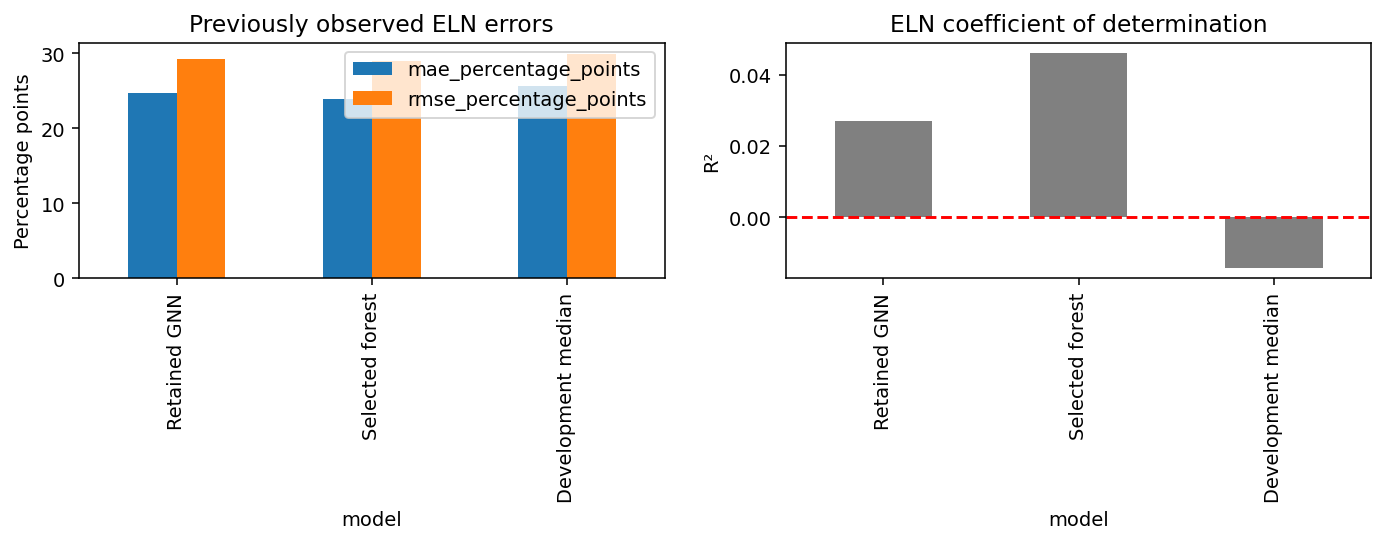

In [2]:
result=read_json('docs/loss-v4/ELN-results.json')
rows=[{'model':'Retained GNN',**result['test_gnn']},{'model':'Selected forest',**result['test_selected_forest']},{'model':'Development median',**result['test_development_median']}]
comparison=pd.DataFrame(rows).set_index('model')
display(comparison)
print('Actual graph checkpoint SHA256:',result['gnn_checkpoint_sha256'])
print('Save/reload example delta:',result['actual_checkpoint_example_delta'])
fig,axes=plt.subplots(1,2,figsize=(10,4))
comparison[['mae_percentage_points','rmse_percentage_points']].plot.bar(ax=axes[0])
comparison.r2.plot.bar(ax=axes[1],color='gray')
axes[0].set(title='Previously observed ELN errors',ylabel='Percentage points')
axes[1].set(title='ELN coefficient of determination',ylabel='R²')
axes[1].axhline(0,color='red',linestyle='--')
show_figure(fig,'reaction_observed_eln_errors')

## Full-source measurement shift
The frozen retained ELN models evaluate every eligible row in the complete 50,688-reaction HTE source. The full cohort includes 2,048 previously observed records, so this is a retrospective evaluation. No adaptation, tuning or selection follows either evaluation.

In [3]:
transfer=read_json('docs/full-hte/results.json')
display(pd.DataFrame([{'model':'GNN',**transfer['gnn']},{'model':'Forest',**transfer['selected_forest']},{'model':'ELN median',**transfer['eln_development_median']}]).set_index('model'))
print('Complete source/retained:',transfer['source_rows'],transfer['retained_rows'])
print('Exclusions:',transfer['dropped'])
print('Previously observed/newly evaluated retained rows:',transfer['previously_observed_retained_rows'],transfer['newly_evaluated_retained_rows'])
print('Scaffold overlap:',transfer['principal_scaffolds_overlapping_eln'],'/',transfer['principal_scaffolds'])
print(transfer['test_exposure'])


,mae_percentage_points,rmse_percentage_points,r2,rows
model,,,,
GNN,23.637401,25.848458,-17.509981,50668
Forest,29.856789,31.027253,-25.670020,50668
ELN median,34.949555,35.350139,-33.619353,50668


Complete source/retained: 50688 50668
Exclusions: {'Need one unambiguous desired-product percentage yield in [0,100]': 20}
Previously observed/newly evaluated retained rows: 2048 48620
Scaffold overlap: 1 / 2
Full cohort includes previously observed lowest-SHA256 2048 source identifiers. Remaining records are newly evaluated, but no fully blind independent test claim. Old subset scores remain historical.


## Actual production inference on a public, illustrative input
This is a hand-written input-only example, not a synthetic quality benchmark or private corpus row. It verifies checkpoint mechanics; the predicted number is not a synthesis guarantee.

In [4]:
from reaction_gnn.train import load_model,predict_record
example={'components':[{'smiles':'Brc1ccccc1','role':0},{'smiles':'Nc1ccccc1','role':0},{'smiles':'CCO','role':2}],'temperature_c':80.}
model=load_model('models/loss-v4/selected.pt')
value=predict_record(model,example)
assert np.isfinite(value) and 0<=value<=100
print('Illustrative predicted yield (%):',value)
print('Finite and bounded checkpoint inference passed; no accuracy claim from this example.')

C:\Users\DELL\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


C:\Users\DELL\AppData\Local\Programs\Python\Python314\Lib\site-packages\torch\jit\_script.py:1485: FutureWarning: `torch.jit.script` is not supported in Python 3.14+ and may break. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Illustrative predicted yield (%): 28.50843071937561
Finite and bounded checkpoint inference passed; no accuracy claim from this example.


## Why negative transfer R² matters
R² compares errors with a constant equal to the evaluation cohort mean. That constant is a hindsight diagnostic, not an eligible transferred model. Large negative R² means the transferred forecasts are much worse than that reference. The source has narrow target variation and changed measurement/chemistry; lower GNN MAE than the transferred forest is not evidence of useful broad generalization. No tuning follows this release.

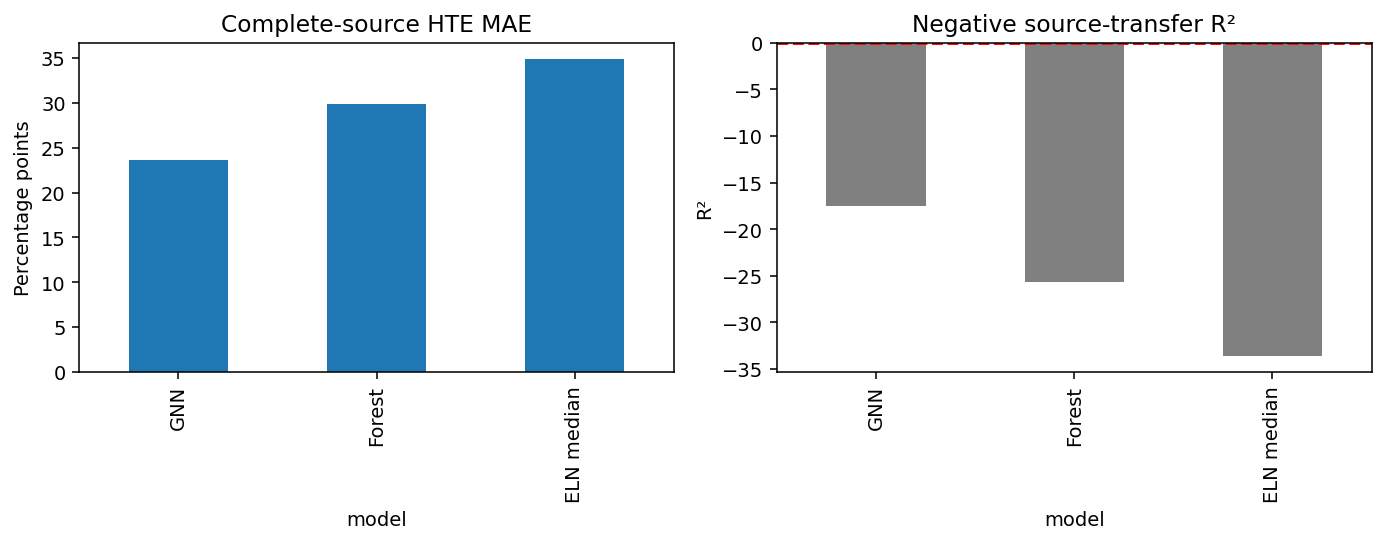

In [5]:
transfer=read_json('docs/full-hte/results.json')
table=pd.DataFrame([{'model':'GNN',**transfer['gnn']},{'model':'Forest',**transfer['selected_forest']},{'model':'ELN median',**transfer['eln_development_median']}]).set_index('model')
fig,axes=plt.subplots(1,2,figsize=(10,4))
table.mae_percentage_points.plot.bar(ax=axes[0])
axes[0].set(title='Complete-source HTE MAE',ylabel='Percentage points')
table.r2.plot.bar(ax=axes[1],color='gray')
axes[1].set(title='Negative source-transfer R²',ylabel='R²')
axes[1].axhline(0,color='red',linestyle='--')
show_figure(fig,'reaction_independent_transfer_errors')

The [primary dataset publication](https://pubs.acs.org/doi/10.1021/jacs.6c05959) specifies two substrate pairs. All 50,688 source rows were processed with frozen ELN-trained models; 50,668 pass the fixed eligibility rule. This is a narrow assay-domain transfer evaluation, not broad chemistry validation.